# Лабораторная работа 3. Сбор данных через REST API
Вариант 3: книги Open Library Search и сведения об авторах Open Library Authors. По умолчанию ноутбук показывает сохранённую выборку без сетевых запросов и без изменения файлов. Исходный код сбора и парного замера приведён в ячейках ниже. [Описание запуска](README.md) · [Отчёт](report.md).


In [1]:
from pathlib import Path
import os, sys, subprocess
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    repo = Path('/content/automated_data_collection_submission')
    if not (repo / '.git').exists():
        subprocess.run(['git', 'clone', '--filter=blob:none', '--sparse',
                        'https://github.com/aginGen/automated_data_collection.git', str(repo)], check=True)
        subprocess.run(['git', '-C', str(repo), 'sparse-checkout', 'set', 'lab3_3'], check=True)
    lab = repo / 'lab3_3'
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(lab / 'requirements.txt')], check=True)
else:
    cwd = Path.cwd()
    lab = cwd if (cwd / 'lab3.ipynb').exists() else cwd / 'lab3_3'
    if not (lab / 'lab3.ipynb').exists():
        raise FileNotFoundError('Откройте ноутбук из папки lab3_3 или корня репозитория')
os.chdir(lab)


## Код сбора
Клиент использует `requests.Session`, таймаут и заголовки. Повторяются только временные HTTP-ошибки 429 и 5xx с увеличивающейся задержкой и учётом Retry-After. Сырые записи Search обогащаются ответами Authors, затем проверяются и сохраняются. Watermark описывает завершённое ограниченное сканирование, а не курсор API: существующие записи не обновляются.


In [2]:
from __future__ import annotations

import argparse
import csv
import random
import re
import threading
from email.utils import parsedate_to_datetime
from typing import Callable

import psutil
import requests
import json
import time
from datetime import datetime, timezone
from pathlib import Path
from urllib.parse import urlsplit
from urllib.robotparser import RobotFileParser

import pandas as pd


def write_json(path: Path, value) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str) + "\n", encoding="utf-8")
    temporary.replace(path)


def write_csv(path: Path, rows: list[dict], fields: list[str] | None = None) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    fields = fields or (list(rows[0]) if rows else [])
    temporary = path.with_suffix(path.suffix + ".tmp")
    with temporary.open("w", encoding="utf-8-sig", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)
    temporary.replace(path)


class APIError(RuntimeError):
    pass


class APIClient:
    LOG_FIELDS = ["page", "url", "params", "status", "records", "duration_s",
                  "timestamp", "attempt", "response_bytes", "retry_delay_s", "error"]

    def __init__(self, timeout: float = 20, interval: float = 0.5, retries: int = 2):
        if timeout <= 0 or interval < 0 or retries < 0:
            raise ValueError("Неверные параметры HTTP-клиента")
        self.timeout = timeout
        self.interval = interval
        self.retries = retries
        self.session = requests.Session()
        self.session.headers.update({
            "User-Agent": "university-data-collection-labs/1.0",
            "Accept": "application/json",
        })
        self.logs: list[dict] = []
        self.rate_headers: dict = {}
        self._last_request = 0.0
        self._robots: dict = {}

    def __enter__(self):
        return self

    def __exit__(self, *args):
        self.session.close()

    @staticmethod
    def retry_delay(value: str | None, attempt: int) -> float:
        backoff = 0.5 * 2 ** attempt + random.uniform(0, 0.25)
        if not value:
            return backoff
        try:
            header_delay = float(value)
        except ValueError:
            try:
                parsed = parsedate_to_datetime(value)
                if parsed.tzinfo is None:
                    parsed = parsed.replace(tzinfo=timezone.utc)
                header_delay = (parsed - datetime.now(timezone.utc)).total_seconds()
            except (ValueError, TypeError, OverflowError):
                header_delay = 0
        return max(backoff, header_delay, 0)

    def check_robots(self, url: str) -> None:
        """Fail closed unless the origin's robots.txt allows this URL.

        A 404 means no robots file and is treated as allowing access. Any
        other non-200 status, redirect or network failure blocks the request.
        """
        parts = urlsplit(url)
        if parts.scheme not in ("http", "https") or not parts.netloc or parts.username:
            raise APIError("Недопустимый адрес для проверки robots.txt")
        origin = f"{parts.scheme.lower()}://{parts.netloc.lower()}"
        if origin not in self._robots:
            pause = self.interval - (time.monotonic() - self._last_request)
            if pause > 0:
                time.sleep(pause)
            self._last_request = time.monotonic()
            robots_url = origin + "/robots.txt"
            try:
                with self.session.get(robots_url, timeout=self.timeout,
                                      allow_redirects=False, stream=True,
                                      headers={"Accept": "text/plain,*/*;q=0.8"}) as response:
                    if response.status_code == 404:
                        self._robots[origin] = None
                    elif response.status_code == 200:
                        media_type = response.headers.get("Content-Type", "").split(";")[0].strip().lower()
                        if media_type in ("text/html", "application/xhtml+xml"):
                            raise APIError("robots.txt содержит HTML")
                        body = bytearray()
                        for chunk in response.iter_content(chunk_size=8192):
                            body.extend(chunk)
                            if len(body) > 512 * 1024:
                                raise APIError("robots.txt больше 512 КиБ")
                        try:
                            text = body.decode("utf-8-sig", errors="strict")
                        except UnicodeDecodeError as error:
                            raise APIError("robots.txt имеет неверную кодировку") from error
                        if not text.strip() or re.search(r"<\s*(?:!doctype\s+html|html\b)", text, re.I):
                            raise APIError("robots.txt пуст или содержит HTML")
                        has_user_agent = False
                        for line in text.splitlines():
                            line = line.split("#", 1)[0].strip()
                            if not line:
                                continue
                            name, separator, value = line.partition(":")
                            name, value = name.strip().lower(), value.strip()
                            if not separator or not re.fullmatch(r"[a-z][a-z0-9_-]*", name):
                                raise APIError("Некорректная директива robots.txt")
                            if name == "user-agent":
                                if not value:
                                    raise APIError("Пустой User-agent в robots.txt")
                                has_user_agent = True
                            elif name in ("allow", "disallow", "crawl-delay", "request-rate"):
                                if not has_user_agent:
                                    raise APIError("Правило robots.txt без User-agent")
                                if name == "crawl-delay" and not value.isdigit():
                                    raise APIError("Некорректный Crawl-delay")
                                if name == "request-rate" and not re.fullmatch(r"[1-9][0-9]*/[1-9][0-9]*", value):
                                    raise APIError("Некорректный Request-rate")
                        if not has_user_agent:
                            raise APIError("В robots.txt нет User-agent")
                        parser = RobotFileParser()
                        parser.set_url(robots_url)
                        parser.parse(text.splitlines())
                        self._robots[origin] = parser
                    else:
                        raise APIError(f"robots.txt недоступен: HTTP {response.status_code}")
            except requests.RequestException as error:
                raise APIError(f"Не удалось проверить robots.txt: {error}") from error
        parser = self._robots[origin]
        if parser is not None and not parser.can_fetch(self.session.headers["User-Agent"], url):
            raise APIError(f"robots.txt запрещает запрос: {url}")

    def get_json(self, url: str, params: dict | None = None, page: int = 0,
                 count: Callable | None = None):
        target = requests.Request("GET", url, params=params).prepare().url
        self.check_robots(target)
        for attempt in range(self.retries + 1):
            pause = self.interval - (time.monotonic() - self._last_request)
            if pause > 0:
                time.sleep(pause)
            self._last_request = time.monotonic()
            started = time.perf_counter()
            entry = dict.fromkeys(self.LOG_FIELDS, "")
            entry.update(page=page, url=url, params=json.dumps(params or {}, ensure_ascii=False),
                         records=0, timestamp=datetime.now(timezone.utc).isoformat(),
                         attempt=attempt + 1, retry_delay_s=0, response_bytes=0)
            try:
                response = self.session.get(url, params=params, timeout=self.timeout, allow_redirects=False)
            except requests.RequestException as error:
                entry.update(duration_s=round(time.perf_counter() - started, 6), error=str(error))
                self.logs.append(entry)
                raise APIError(f"Сетевая ошибка {url}: {error}") from error
            with response:
                body = response.content
                entry.update(url=response.url, status=response.status_code,
                             response_bytes=len(body),
                             duration_s=round(time.perf_counter() - started, 6))
                self.rate_headers.update({
                    key: value for key, value in response.headers.items()
                    if "ratelimit" in key.lower() or key.lower() == "retry-after"
                })
                temporary_error = response.status_code == 429 or 500 <= response.status_code <= 599
                snippet = body[:200].decode("utf-8", errors="replace")
                if not 200 <= response.status_code <= 299:
                    entry["error"] = f"HTTP {response.status_code}: {snippet}"
                    if temporary_error and attempt < self.retries:
                        delay = self.retry_delay(response.headers.get("Retry-After"), attempt)
                        entry["retry_delay_s"] = round(delay, 6)
                        self.logs.append(entry)
                        time.sleep(delay)
                        continue
                    self.logs.append(entry)
                    raise APIError(f"{url}: {entry['error']}")
                media_type = response.headers.get("Content-Type", "").split(";")[0].strip().lower()
                if media_type != "application/json" and not media_type.endswith("+json"):
                    entry["error"] = f"Ожидался JSON, получен {media_type}: {snippet}"
                    self.logs.append(entry)
                    raise APIError(f"{url}: {entry['error']}")
                try:
                    payload = response.json()
                    entry["records"] = count(payload) if count else (len(payload) if isinstance(payload, list) else 1)
                except (ValueError, KeyError, TypeError) as error:
                    entry["error"] = f"Неверный JSON или структура: {snippet}"
                    self.logs.append(entry)
                    raise APIError(f"{url}: {entry['error']}") from error
                self.logs.append(entry)
                return payload, dict(response.headers)
        raise APIError("Исчерпаны попытки запроса")

    def save_log(self, path: Path) -> None:
        write_csv(path, self.logs, self.LOG_FIELDS)

    def metrics(self) -> dict:
        return {
            "requests": len(self.logs),
            "response_bytes": sum(int(row["response_bytes"]) for row in self.logs),
            "retries": sum(int(row["attempt"]) > 1 for row in self.logs),
            "status_counts": {
                str(code): sum(row["status"] == code for row in self.logs)
                for code in sorted({row["status"] for row in self.logs}, key=str)
            },
            "rate_headers": self.rate_headers,
        }


def paginate(client: APIClient, url: str, extract: Callable, make_params: Callable,
             page_size: int, max_records: int, max_pages: int,
             total: Callable | None = None) -> list[dict]:
    if min(page_size, max_records, max_pages) <= 0:
        raise ValueError("Предохранители пагинации должны быть положительными")
    records: list[dict] = []
    offset = 0
    for page in range(1, max_pages + 1):
        limit = min(page_size, max_records - len(records))
        payload, _ = client.get_json(url, make_params(page, offset, limit), page,
                                     count=lambda body: len(extract(body)))
        batch = extract(payload)
        if not isinstance(batch, list):
            raise APIError("Массив записей отсутствует в ответе")
        if not batch:
            break
        records.extend(batch[:max_records - len(records)])
        offset += len(batch)
        if len(records) >= max_records or (total and offset >= total(payload)):
            break
    return records


def search_docs(body: dict) -> list[dict]:
    """Validate Search payload while the HTTP response can still be logged."""
    if not isinstance(body, dict) or not isinstance(body.get("docs"), list):
        raise ValueError("Search docs must be an array")
    if isinstance(body.get("numFound"), bool) or not isinstance(body.get("numFound"), int) or body["numFound"] < 0:
        raise ValueError("Search numFound must be a nonnegative integer")
    docs = body["docs"]
    if any(not isinstance(row, dict) or not isinstance(row.get("key"), str) or not row["key"].strip() for row in docs):
        raise ValueError("Search documents must have a nonempty key")
    return docs


class MemorySampler:
    def __init__(self, pid: int | None = None):
        self.process = psutil.Process(pid)
        self.peak_bytes = 0
        self.stop = threading.Event()
        self.thread = threading.Thread(target=self._run, daemon=True)

    def _sample(self):
        processes = [self.process]
        try:
            processes += self.process.children(recursive=True)
        except (psutil.NoSuchProcess, psutil.AccessDenied):
            return
        rss = 0
        for process in processes:
            try:
                rss += process.memory_info().rss
            except (psutil.NoSuchProcess, psutil.AccessDenied):
                continue
        self.peak_bytes = max(self.peak_bytes, rss)

    def _run(self):
        while not self.stop.wait(0.05):
            self._sample()

    def __enter__(self):
        self._sample()
        self.thread.start()
        return self

    def __exit__(self, *args):
        self._sample()
        self.stop.set()
        self.thread.join(timeout=2)

    @property
    def peak_mib(self):
        return round(self.peak_bytes / 1024 ** 2, 3)


ROOT = Path.cwd()
SEARCH_URL = "https://openlibrary.org/search.json"
FIELDS = "key,title,author_key,author_name,first_publish_year,language,edition_count"
REQUIRED = ["work_id", "title", "url", "edition_count"]


def normalize_books(raw: list[dict], author_cache: dict) -> tuple[pd.DataFrame, pd.DataFrame]:
    books = pd.json_normalize(raw, sep="_")
    def column(name):
        return books[name] if name in books else pd.Series([None] * len(raw), dtype="object")

    def items(row, name):
        value = row.get(name)
        return value if isinstance(value, list) else []

    flat = pd.DataFrame({
        "work_id": column("key"),
        "title": column("title").map(lambda value: " ".join(value.split()) if isinstance(value, str) else None),
        "first_publish_year": pd.to_numeric(column("first_publish_year"), errors="coerce").astype("Int64"),
        "edition_count": pd.to_numeric(column("edition_count"), errors="coerce").astype("Int64"),
        "author_key": [items(row, "author_key")[0] if items(row, "author_key") else "" for row in raw],
        "author_name_catalogue": [items(row, "author_name")[0] if items(row, "author_name") else "" for row in raw],
        "author_count": [len(items(row, "author_key")) for row in raw],
        "language_count": [len(items(row, "language")) for row in raw],
        "languages": [";".join(x for x in items(row, "language") if isinstance(x, str)) for row in raw],
        "collected_at": [row.get("collected_at") for row in raw],
    })
    flat["url"] = "https://openlibrary.org" + flat["work_id"].astype("string")
    author_rows = [{
        "author_key": key,
        "author_name_verified": value.get("name"),
        "author_revision": value.get("revision"),
        "author_modified_at": value.get("last_modified", {}).get("value"),
        "author_url": "https://openlibrary.org/authors/" + key,
    } for key, value in author_cache.items()]
    authors = pd.json_normalize(author_rows, sep="_")
    if authors.empty:
        authors = pd.DataFrame(columns=["author_key", "author_name_verified", "author_revision",
                                       "author_modified_at", "author_url"])
    before = len(flat)
    flat = flat.merge(authors, on="author_key", how="left", validate="many_to_one", indicator=True)
    if len(flat) != before:
        raise ValueError("Обогащение изменило число книг")
    flat["author_matched"] = flat.pop("_merge").eq("both")
    flat["collected_at"] = pd.to_datetime(flat["collected_at"], utc=True, errors="raise")
    flat["author_modified_at"] = pd.to_datetime(flat["author_modified_at"], utc=True, errors="coerce", format="mixed")
    flat["author_revision"] = pd.to_numeric(flat["author_revision"], errors="coerce").astype("Int64")
    language_rows = [{**row, "language": items(row, "language"), "key": row.get("key"), "title": row.get("title")} for row in raw]
    languages = pd.json_normalize(language_rows, record_path="language",
                                  meta=["key", "title"], errors="ignore", sep="_")
    languages = languages.rename(columns={0: "language", "key": "work_id"})
    if "language" not in languages:
        languages["language"] = pd.Series(dtype="object")
    languages = languages.drop_duplicates(["work_id", "language"])
    return flat, languages


def quality(books: pd.DataFrame) -> dict:
    current_year = datetime.now(timezone.utc).year
    checks = {
        "edition_count_positive": books["edition_count"].gt(0).fillna(False),
        "publication_year_not_future": books["first_publish_year"].le(current_year) | books["first_publish_year"].isna(),
        "valid_work_key": books["work_id"].astype("string").str.fullmatch(r"/works/OL\d+W").fillna(False),
        "nonempty_title": books["title"].astype("string").str.strip().ne("").fillna(False),
    }
    complete = {
        name: round(float((column.notna() & column.astype(str).str.strip().ne("")).mean() * 100), 2)
        for name, column in books.items()
    }
    return {
        "rows": len(books),
        "unique_keys": books["work_id"].nunique(),
        "duplicates": int(books.duplicated("work_id").sum()),
        "completeness_percent": complete,
        "required_empty_rows": int(books[REQUIRED].apply(lambda col: col.isna() | col.astype("string").str.strip().eq("").fillna(False)).any(axis=1).sum()),
        "business_rule_violations": {name: int((~values).sum()) for name, values in checks.items()},
        "author_matches": int(books["author_matched"].sum()),
        "types": {name: str(dtype) for name, dtype in books.dtypes.items()},
    }


def find_outliers(books: pd.DataFrame) -> dict:
    fields = []
    for name in ("first_publish_year", "edition_count"):
        values = pd.to_numeric(books[name], errors="coerce").dropna()
        if values.empty:
            fields.append({"field": name, "q1": None, "q3": None, "lower": None,
                           "upper": None, "flagged": 0, "removed": 0})
            continue
        q1, q3 = float(values.quantile(.25)), float(values.quantile(.75))
        lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        fields.append({"field": name, "q1": q1, "q3": q3, "lower": lower,
                       "upper": upper, "flagged": int(((values < lower) | (values > upper)).sum()), "removed": 0})
    return {"method": "1.5 IQR; flags are candidates for review, not removed", "fields": fields}


def save_frame(frame: pd.DataFrame, path: Path) -> None:
    output = frame.copy()
    for name in output:
        if isinstance(output[name].dtype, pd.DatetimeTZDtype):
            output[name] = output[name].map(lambda value: value.isoformat() if pd.notna(value) else None)
    rows = output.astype(object).where(output.notna(), None).to_dict("records")
    write_csv(path, rows, list(output.columns))


def collect(output: Path, query: str = "python programming",
            page_size: int = 90, max_records: int = 360, max_pages: int = 20,
            run_label: str = "initial", interval: float = 1.1) -> dict:
    output.mkdir(parents=True, exist_ok=True)
    state_path = output / "state.json"
    state_exists = state_path.exists()
    state = json.loads(state_path.read_text(encoding="utf-8")) if state_exists else {
        "query": query, "seen_work_ids": [], "watermark": None,
    }
    if state["query"] != query:
        raise ValueError("Для другого поискового запроса используйте отдельную папку --output")
    old_raw = []
    raw_path = output / "data_raw.jsonl"
    if raw_path.exists():
        old_raw = [json.loads(line) for line in raw_path.read_text(encoding="utf-8").splitlines() if line]
    old_ids = {row["key"] for row in old_raw}
    state_ids = set(state["seen_work_ids"])
    pending_path = output / "collection_identity.json"
    pending = json.loads(pending_path.read_text(encoding="utf-8")) if pending_path.exists() else None
    if not state_ids.issubset(old_ids):
        raise ValueError("В состоянии есть ключи, отсутствующие в сырых данных")
    if old_ids != state_ids:
        # A missing first state is recoverable only with the query marker saved before raw.
        if not state_exists and not (pending and pending.get("query") == query):
            raise ValueError("Невозможно проверить запрос для сырых данных без состояния")
        print("Предупреждение: обнаружен незавершённый сбор; восстанавливаем таблицы и состояние из сырых данных.", flush=True)
    cache_path = output / "authors_cache.json"
    author_cache = json.loads(cache_path.read_text(encoding="utf-8")) if cache_path.exists() else {}
    started = time.perf_counter()
    with MemorySampler() as memory, APIClient(interval=interval) as client:
        try:
            fetched = paginate(
                client, SEARCH_URL, search_docs,
                lambda page, offset, limit: {"q": query, "offset": offset, "limit": limit,
                                            "fields": FIELDS, "sort": "key"},
                page_size, max_records, max_pages, total=lambda body: int(body["numFound"]),
            )
            new = {row["key"]: row for row in fetched if row["key"] not in old_ids}
            for row in new.values():
                row["collected_at"] = datetime.now(timezone.utc).isoformat()
            raw = old_raw + list(new.values())
            keys = sorted({
                row["author_key"][0] for row in raw if row.get("author_key")
            } - set(author_cache))
            for index, key in enumerate(keys, 1):
                body, _ = client.get_json(f"https://openlibrary.org/authors/{key}.json",
                                         page=0, count=lambda body: 1)
                author_cache[key] = {
                    name: body[name] for name in ["key", "name", "revision", "last_modified", "type"]
                    if name in body
                }
                write_json(cache_path, author_cache)
                if index % 25 == 0:
                    print(f"Authors: {index}/{len(keys)}", flush=True)
            books, languages = normalize_books(raw, author_cache)
            report = quality(books)
            if report["duplicates"] or report["required_empty_rows"]:
                raise ValueError("Проверка ключей или обязательных полей не пройдена")
            if len(books) < 300:
                raise ValueError(f"Получено {len(books)} книг, требуется не менее 300")
            if new:
                # Records may reach disk before the state; persist the query for first-run recovery.
                write_json(pending_path, {"query": query})
                temporary = raw_path.with_suffix(".jsonl.tmp")
                temporary.write_text("\n".join(json.dumps(row, ensure_ascii=False) for row in raw) + "\n", encoding="utf-8")
                temporary.replace(raw_path)
            # Derived outputs are rebuilt even when the bounded scan finds no new keys.
            save_frame(books, output / "data_clean.csv")
            save_frame(languages, output / "book_languages.csv")
            write_json(output / "quality.json", report)
            write_json(output / "outliers.json", find_outliers(books))
            write_csv(output / "completeness.csv", [
                {"field": field, "completeness_percent": value}
                for field, value in report["completeness_percent"].items()
            ])
            # The marker describes a completed scan; it is not an API cursor.
            write_json(state_path, {
                "query": query,
                "seen_work_ids": sorted(old_ids | new.keys()),
                "watermark": {"last_completed_offset": len(fetched),
                              "last_work_id": fetched[-1]["key"] if fetched else None},
            })
            result = {
                "run": run_label, "query": query, "fetched": len(fetched),
                "new_records": len(new), "total_rows": len(books),
                "search_pages": sum(row["page"] > 0 and row["status"] == 200 for row in client.logs),
                "language_rows": len(languages), "merge_rows_before": len(raw),
                "merge_rows_after": len(books),
                "duration_s": round(time.perf_counter() - started, 4),
                **client.metrics(),
            }
        finally:
            client.save_log(output / f"collection_log{'' if run_label == 'initial' else '_' + run_label}.csv")
    result["peak_memory_mib"] = memory.peak_mib
    write_json(output / f"metrics_{run_label}.json", result)
    print(json.dumps(result, ensure_ascii=False, indent=2), flush=True)
    return result



def show_headers(query: str = "python programming") -> dict:
    with APIClient(interval=1.1) as client:
        _, headers = client.get_json(
            SEARCH_URL,
            {"q": query, "limit": 1, "fields": "key,title", "sort": "key"},
            count=lambda body: len(body["docs"]),
        )
        selected = {
            name: value for name, value in headers.items()
            if name.lower() == "content-type" or name.lower() == "retry-after"
            or "ratelimit" in name.lower()
        }
        result = {
            "request": {
                "method": "GET",
                "url": client.logs[-1]["url"],
                "headers": {
                    name: client.session.headers[name] for name in ("User-Agent", "Accept")
                },
            },
            "response": {"status": client.logs[-1]["status"], "headers": selected},
            "rate_headers": client.rate_headers,
        }
    print(json.dumps(result, ensure_ascii=False, indent=2))
    return result



## Код сопоставимого замера
Этот вариант запрашивает только Search: четыре страницы по 90 книг и пять итоговых полей. Он нужен для сравнения с n8n; получение авторов в него не входит.


In [3]:
"""Measure the same Search-only, 360-book task as the n8n workflow."""
import argparse
from datetime import datetime, timezone
import json
from pathlib import Path
import time

import pandas as pd



class PageCooldownClient(APIClient):
    def get_json(self, *args, **kwargs):
        # n8n requestInterval waits after a response, rather than only between
        # request starts. Match that policy for the Search-only comparison.
        if self.logs:
            time.sleep(1.1)
        return super().get_json(*args, **kwargs)


def project_books(raw: list[dict]) -> pd.DataFrame:
    flat = pd.json_normalize(raw, sep='_')
    def numeric(name):
        values = flat[name] if name in flat else pd.Series(None, index=flat.index, dtype='object')
        return pd.to_numeric(values, errors='coerce').astype('Int64')
    return pd.DataFrame({
        'work_id': flat['key'],
        'title': flat['title'].map(lambda value: ' '.join(value.split()) if isinstance(value, str) else None),
        'first_publish_year': numeric('first_publish_year'),
        'edition_count': numeric('edition_count'),
        'url': 'https://openlibrary.org' + flat['key'],
    })


def benchmark(output: Path) -> dict:
    output.mkdir(parents=True, exist_ok=True)
    started_at = datetime.now(timezone.utc).isoformat()
    started = time.perf_counter()
    with PageCooldownClient(timeout=25, interval=1.1) as client:
        try:
            raw = paginate(
                client, SEARCH_URL, search_docs,
                lambda page, offset, limit: {
                    'q': 'python programming', 'offset': offset, 'limit': limit,
                    'fields': FIELDS, 'sort': 'key',
                },
                page_size=90, max_records=360, max_pages=4,
                total=lambda body: int(body['numFound']),
            )
            if len(raw) != 360 or len({row['key'] for row in raw}) != 360:
                raise ValueError('Expected 360 unique books for the comparison')
            table = project_books(raw)
            if table[['work_id', 'title', 'edition_count']].isna().any().any():
                raise ValueError('A required output field is missing')
            save_frame(table, output / 'data_clean.csv')
            measured_duration = time.perf_counter() - started
            (output / 'data_raw.jsonl').write_text(
                '\n'.join(json.dumps(row, ensure_ascii=False) for row in raw) + '\n', encoding='utf-8')
            pages = [row for row in client.logs if row['page'] > 0 and row['status'] == 200]
            if len(pages) != 4 or [row['records'] for row in pages] != [90] * 4:
                raise ValueError('Expected four successful Search pages of 90 records')
            summary = {
                'scope': 'Search API only; same query, fields, 4x90 pages and CSV columns as n8n; Authors API excluded',
                'started_at': started_at, 'stopped_at': datetime.now(timezone.utc).isoformat(),
                'rows': len(table), 'unique_ids': int(table['work_id'].nunique()),
                'search_pages': len(pages), 'page_sizes': [row['records'] for row in pages],
                'duration_s': round(measured_duration, 4),
                'rate_policy': '1.1 seconds after each page response before the next page request',
                'fields': FIELDS, 'query': 'python programming', 'sort': 'key',
                **client.metrics(),
            }
        finally:
            client.save_log(output / 'collection_log.csv')
    write_json(output / 'metrics.json', summary)
    print(json.dumps(summary, ensure_ascii=False, indent=2))
    return summary



## Выбор режима
По умолчанию показан сохранённый срез. Для нового полного сбора установите `RUN_COLLECTION = True`: создаётся отдельная временная папка, потребуется сеть и несколько минут. `RUN_REPEAT = True` дополнительно повторит сбор в той же папке. `RUN_BENCHMARK = True` выполняет отдельный Search-only замер во временной папке. Публичные файлы не перезаписываются.


In [4]:
import tempfile
import matplotlib.pyplot as plt
RUN_COLLECTION = False
RUN_REPEAT = False
RUN_BENCHMARK = False
snapshot = json.loads(Path('lab3.ipynb').read_text(encoding='utf-8'))['metadata']['lab3_snapshot']
if RUN_REPEAT and not RUN_COLLECTION:
    raise ValueError('Для повтора включите RUN_COLLECTION')
if RUN_COLLECTION:
    data_dir = Path(tempfile.mkdtemp(prefix='lab3_collection_'))
    result = collect(output=data_dir, run_label='fresh')
    if RUN_REPEAT:
        repeat = collect(output=data_dir, run_label='repeat')
else:
    data_dir = Path('.')
    result = snapshot['metrics_initial']
    repeat = snapshot['metrics_second']
if RUN_BENCHMARK:
    benchmark_dir = Path(tempfile.mkdtemp(prefix='lab3_search_'))
    benchmark_result = benchmark(benchmark_dir)


## Источник и страницы
Search API возвращает JSON по запросу `python programming`, параметрам `offset` и `limit`; Authors API возвращает сведения по ключу автора. API-ключ не требуется. Страница — порция результатов; задержка между запросами ограничивает нагрузку на источник. Ниже показан журнал сохранённого или нового сбора.


In [5]:
log_name = 'collection_log_fresh.csv' if RUN_COLLECTION else 'collection_log.csv'
page_log = pd.read_csv(data_dir / log_name)
page_log = page_log[pd.to_numeric(page_log['page'], errors='coerce').fillna(0).gt(0)]
display(page_log[['page', 'records', 'duration_s']].rename(columns={'page':'Страница', 'records':'Книг', 'duration_s':'Время, с'}))


,Страница,Книг,"Время, с"
0,1,90,3.183714
1,2,90,2.783779
2,3,90,0.360306
3,4,90,0.461147


## Нормализация и качество
`json_normalize` раскрывает JSON в таблицу, а массив языков — в отдельные строки. Для первого автора выполняется объединение many-to_one: одной книге соответствует не более одной строки обогащения. Полнота показывает долю непустых значений. IQR — межквартильный размах; флаги по правилу 1,5 IQR отмечают кандидатов на проверку, но не доказывают ошибку и не удаляют данные.


In [6]:
raw = [json.loads(line) for line in (data_dir / 'data_raw.jsonl').read_text(encoding='utf-8').splitlines() if line]
author_cache = (json.loads((data_dir / 'authors_cache.json').read_text(encoding='utf-8'))
                if RUN_COLLECTION else snapshot['authors_cache'])
state = json.loads((data_dir / 'state.json').read_text(encoding='utf-8'))
assert set(state['seen_work_ids']) == {row['key'] for row in raw}
data, languages = normalize_books(raw, author_cache)
quality_report = quality(data)
outliers = find_outliers(data)
# Исходная итоговая таблица входит в комплект; она должна совпадать по ключам с raw.
saved_data = pd.read_csv(data_dir / 'data_clean.csv')
assert set(saved_data['work_id']) == set(data['work_id'])
display(data[['work_id','title','first_publish_year','edition_count','author_name_verified']].head())
display(pd.DataFrame(quality_report['completeness_percent'].items(), columns=['Поле','Полнота, %']))
display(pd.DataFrame(outliers['fields']))
print('Дубли:', quality_report['duplicates'], '; строки с пустыми обязательными полями:', quality_report['required_empty_rows'])
print('Нарушения правил:', quality_report['business_rule_violations'])


,work_id,title,first_publish_year,edition_count,author_name_verified
0,/works/OL10056472W,Bioinformatics Programming in Python,1991,4,Ruediger-Marcus Flaig
1,/works/OL1033722W,XML Processing with Python,2000,2,Sean McGrath
2,/works/OL10538818W,The life of Python,1986,2,George Perry
3,/works/OL106747W,Python scripting for computational science,2004,2,Hans Petter Langtangen
4,/works/OL11791152W,Python for bioinformatics,2009,1,Jason M. Kinser


,Поле,"Полнота, %"
0,work_id,100.00
1,title,100.00
2,first_publish_year,100.00
3,edition_count,100.00
4,author_key,99.17
5,author_name_catalogue,99.17
6,author_count,100.00
7,language_count,100.00
8,languages,60.00
9,collected_at,100.00


,field,q1,q3,lower,upper,flagged,removed
0,first_publish_year,2010.0,2018.0,1998.0,2030.0,11,0
1,edition_count,1.0,2.0,-0.5,3.5,50,0


Дубли: 0 ; строки с пустыми обязательными полями: 0
Нарушения правил: {'edition_count_positive': 0, 'publication_year_not_future': 0, 'valid_work_key': 0, 'nonempty_title': 0}


## Анализ годов и языков
Показатели относятся только к первым результатам по ключу, а не ко всему каталогу. Год — первое издание; отсутствие записи языка не означает отсутствие языка у книги.


,Показатель,Значение
0,Книг,360.0
1,Известен год,360.0
2,Медианный год,2013.0
3,Указан язык,216.0
4,Английский,207.0


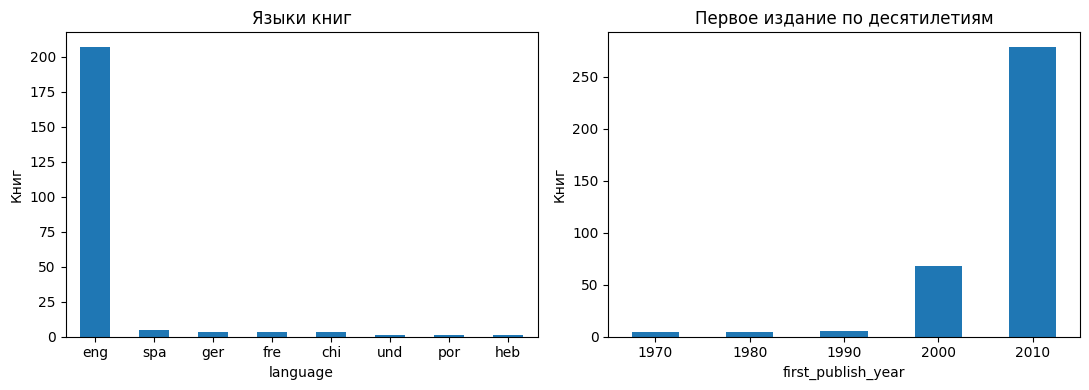

In [7]:
years = pd.to_numeric(data['first_publish_year'], errors='coerce').dropna().astype(int)
decades = ((years // 10) * 10).value_counts().sort_index()
summary = {'Книг':len(data), 'Известен год':len(years), 'Медианный год':years.median(),
           'Указан язык':languages['work_id'].nunique(), 'Английский':int(languages['language'].eq('eng').sum())}
display(pd.DataFrame(summary.items(), columns=['Показатель','Значение']))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, values, title in [(axes[0], languages['language'].value_counts().head(8), 'Языки книг'),
                            (axes[1], decades, 'Первое издание по десятилетиям')]:
    if values.empty:
        axis.text(.5, .5, 'Нет данных', ha='center', va='center', transform=axis.transAxes)
        axis.set_title(title); axis.set_xticks([])
    else:
        values.plot.bar(ax=axis, title=title, rot=0)
    axis.set_ylabel('Книг')
fig.tight_layout(); plt.show()


## Python и n8n: сопоставимый сбор 360 книг
Оба замера используют один запрос, набор полей и четыре страницы по 90 книг; оба сохраняют пять полей, без запросов Authors. Ниже сравниваются исторические снимки, поэтому новый запуск API не меняет эту проверку. Каждый замер сделан один раз: сеть и кэш влияют на результат. Снимки n8n в папке `nocode` относятся к раннему сценарию на 30 книг.


In [8]:
python_search = pd.DataFrame(snapshot['python_search_rows'])
nocode = pd.read_csv('nocode/nocode_result.csv', dtype=str, keep_default_na=False)
fields = ['title', 'first_publish_year', 'edition_count', 'url']
joined = nocode.merge(python_search[['work_id'] + fields], on='work_id', how='left', suffixes=('_n8n','_python'), validate='one_to_one', indicator=True)
print('Книг n8n:', len(nocode), '; совпадений по ключу:', int(joined['_merge'].eq('both').sum()))
for field in fields:
    print(field, ': совпадений', int(joined[field + '_n8n'].eq(joined[field + '_python']).sum()))
comparison = pd.DataFrame([
    {'Подход':'Python Search-only', 'Книг':snapshot['python_search_metrics']['rows'], 'Страниц':snapshot['python_search_metrics']['search_pages'], 'Время, с':snapshot['python_search_metrics']['duration_s']},
    {'Подход':'n8n Search-only', 'Книг':snapshot['n8n_metrics']['rows'], 'Страниц':snapshot['n8n_metrics']['emitted_pages'], 'Время, с':snapshot['n8n_metrics']['duration_s']},
])
display(comparison)
display(pd.DataFrame([{'Подход':'Python', 'Разработка, мин':snapshot['development_metrics']['python_minutes']},
                      {'Подход':'n8n', 'Разработка, мин':snapshot['development_metrics']['n8n_minutes']}]))
print('Время разработки — оценка автора, не автоматический замер.')


Книг n8n: 360 ; совпадений по ключу: 360
title : совпадений 360
first_publish_year : совпадений 360
edition_count : совпадений 360
url : совпадений 360


,Подход,Книг,Страниц,"Время, с"
0,Python Search-only,360,4,14.5995
1,n8n Search-only,360,4,39.2610


,Подход,"Разработка, мин"
0,Python,120
1,n8n,60


Время разработки — оценка автора, не автоматический замер.


## Вывод
Основной исторический набор содержит 360 книг; обогащение и показатели качества рассчитываются выше по сохранённым данным. Сравнение Search-only характеризует конкретные два запуска, а не универсальную скорость инструментов. Python позволяет выполнять более подробную обработку; n8n удобен для визуального сценария и расписания. Подробности и ограничения приведены в [отчёте](report.md).


In [ ]:
print('Текущий набор: книг', len(data), '; сопоставлено первых авторов', int(data['author_matched'].sum()))

Текущий набор: книг 360 ; сопоставлено первых авторов 357
